# 00 — Dataset Setup and Augmentation Pipeline

**Project:** Bangladeshi Freshwater Fish Image Classification Using CNN and Transfer Learning

**Group Members:**
1. Swapnil Santosh Akhade
2. Mansi Somani
3. Vivek Singh

**Dataset:** Bangladeshi Freshwater Fish Image Dataset (BFF-15)

**Owner:** Swapnil Santosh Akhade (dataset preparation)

---

## Purpose of this notebook

This notebook is the **shared data foundation** for both models:

- `01_custom_cnn.ipynb` (Vivek) — CNN from scratch
- `02_transfer_learning.ipynb` (Mansi) — fine-tuned pretrained model

Both notebooks must load data through this notebook's outputs, so that:

- the **class mapping** is identical,
- the **train / validation / test split** is identical,
- the **augmentation pipeline** is identical.

This guarantees a fair comparison later in `03_comparison.ipynb`.

## What this notebook does

1. Scans the raw dataset and verifies image counts, sizes, and formats.
2. Builds a reproducible, stratified train/validation/test split.
3. Saves the splits to CSV so both model notebooks reuse them.
4. Defines the `tf.data` input pipeline and on-the-fly augmentation.
5. Saves pipeline configuration for reproducibility.

## What this notebook does **not** do

- It does not build, compile, or train any model.
- It does not modify the raw dataset on disk.

## 1. Environment and Imports

We import standard libraries and the shared `data_utils` module from the project root.

In [1]:
import sys, json, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

from PIL import Image
from collections import Counter

import tensorflow as tf

# Make the project root importable so we can `from data_utils import ...`
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT))

from data_utils import (
    DATA_DIR, SPLITS_DIR,
    CLASS_NAMES, CLASS_TO_IDX, IDX_TO_CLASS,
    IMG_SIZE, BATCH_SIZE, SEED,
    scan_dataset,
)

print("TensorFlow:", tf.__version__)
print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR:", DATA_DIR)
print("SPLITS_DIR:", SPLITS_DIR)
print("Num classes:", len(CLASS_NAMES))
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Seed:", SEED)

TensorFlow: 2.21.0
PROJECT_ROOT: d:\Dev\College\GenAI\bangladeshi-fish-cnn-classification
DATA_DIR: D:\Dev\College\GenAI\bangladeshi-fish-cnn-classification\data\raw
SPLITS_DIR: D:\Dev\College\GenAI\bangladeshi-fish-cnn-classification\data\splits
Num classes: 15
Image size: (224, 224)
Batch size: 32
Seed: 42


## 2. Dataset Scanning

We walk `data/raw/` assuming one folder per class.

Expected layout:

data/raw/     
├── GRASS CARP/    
├── ILISH/    
├── KATLA/    
├── ...    
└── TENGRA/    

The scanner returns a DataFrame with one row per image: `filepath`, `label`, `class_name`.

In [2]:
df = scan_dataset()

print("Total images:", len(df))
print()
print("Per-class counts:")
print(df.groupby("class_name").size().reindex(CLASS_NAMES))

# basic integrity
print()
print("Unique labels:", sorted(df["label"].unique()))
print("Missing values:", df.isnull().sum().sum())
print("Duplicate filepaths:", df["filepath"].duplicated().sum())

Total images: 5577

Per-class counts:
class_name
GRASS CARP     403
ILISH          233
KATLA          427
KOI            434
MAGUR          282
MIRROR CARP    259
MRIGAL         317
PABDA          348
PANGAS         510
PUTI           409
RUI            514
SHOL           296
SILVER CARP    240
TELAPIA        383
TENGRA         522
dtype: int64

Unique labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14)]
Missing values: 0
Duplicate filepaths: 0


## 3. Visual sanity check — one image per class

We display one representative image per class to confirm the folder-to-class mapping is correct.

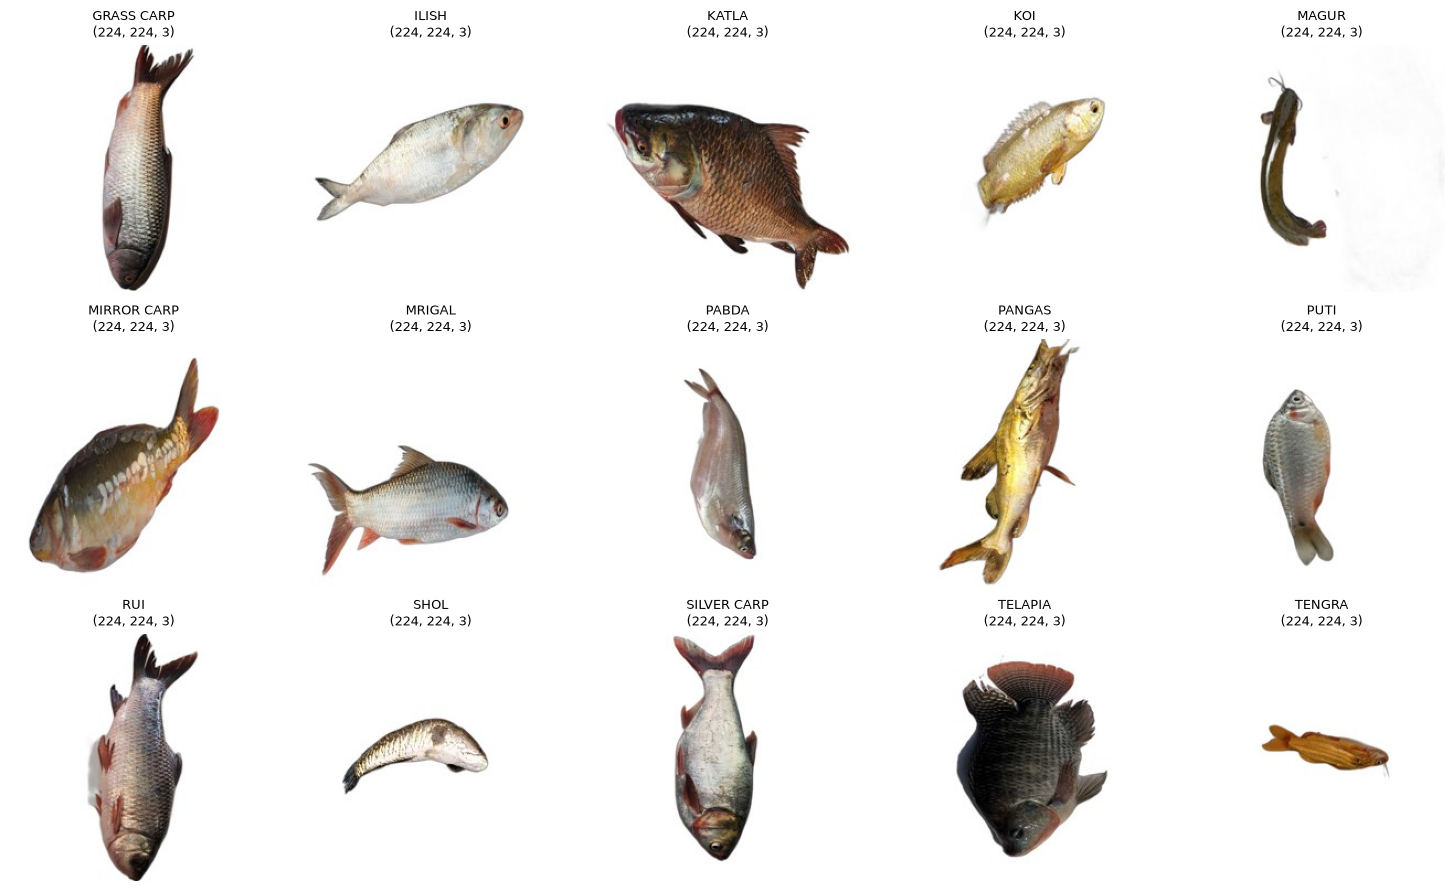

In [3]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
axes = axes.ravel()
for i, cls in enumerate(CLASS_NAMES):
    sample = df[df["class_name"] == cls].iloc[0]
    img = mpimg.imread(sample["filepath"])
    axes[i].imshow(img)
    axes[i].set_title(f"{cls}\n{img.shape}", fontsize=9)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

## 4. Image size, mode, and readability check

We sample 200 random images and verify:

- all are the same size,
- all are RGB,
- none are corrupted.

In [4]:
random.seed(SEED)
sample = df.sample(n=200, random_state=SEED)

sizes  = Counter()
modes  = Counter()
broken = []

for _, row in sample.iterrows():
    try:
        with Image.open(row["filepath"]) as im:
            sizes[im.size] += 1
            modes[im.mode] += 1
    except Exception as e:
        broken.append((row["filepath"], str(e)))

print("Top image sizes (w, h):")
for s, c in sizes.most_common(10):
    print(f"  {s}: {c}")

print()
print("Modes:", dict(modes))
print()
print("Broken files:", len(broken))
for path, err in broken[:5]:
    print("  ", path, "->", err)

Top image sizes (w, h):
  (224, 224): 200

Modes: {'RGB': 200}

Broken files: 0


## 5. Save scan summary

We save the per-class counts and totals to `custom_cnn/metrics/dataset_scan.csv`.

This same file is regenerated inside the transfer-learning folder for symmetry later.

In [5]:
CUSTOM_CNN_DIR      = PROJECT_ROOT / "custom_cnn"
TRANSFER_DIR        = PROJECT_ROOT / "transfer_learning"
CUSTOM_METRICS_DIR  = CUSTOM_CNN_DIR / "metrics"
TRANSFER_METRICS_DIR = TRANSFER_DIR / "metrics"

CUSTOM_METRICS_DIR.mkdir(parents=True, exist_ok=True)
TRANSFER_METRICS_DIR.mkdir(parents=True, exist_ok=True)

scan_summary = (
    df.groupby("class_name")
      .size()
      .reindex(CLASS_NAMES)
      .rename("count")
      .reset_index()
)
scan_summary.loc[len(scan_summary)] = ["TOTAL", len(df)]

scan_summary.to_csv(CUSTOM_METRICS_DIR / "dataset_scan.csv", index=False)
scan_summary.to_csv(TRANSFER_METRICS_DIR / "dataset_scan.csv", index=False)

print(scan_summary)
print()
print("Saved:", CUSTOM_METRICS_DIR / "dataset_scan.csv")
print("Saved:", TRANSFER_METRICS_DIR / "dataset_scan.csv")

     class_name  count
0    GRASS CARP    403
1         ILISH    233
2         KATLA    427
3           KOI    434
4         MAGUR    282
5   MIRROR CARP    259
6        MRIGAL    317
7         PABDA    348
8        PANGAS    510
9          PUTI    409
10          RUI    514
11         SHOL    296
12  SILVER CARP    240
13      TELAPIA    383
14       TENGRA    522
15        TOTAL   5577

Saved: d:\Dev\College\GenAI\bangladeshi-fish-cnn-classification\custom_cnn\metrics\dataset_scan.csv
Saved: d:\Dev\College\GenAI\bangladeshi-fish-cnn-classification\transfer_learning\metrics\dataset_scan.csv


## 6. Stratified train / validation / test split

We use a **70 / 15 / 15** stratified split so:

- every class keeps the same proportion in every split,
- both model notebooks train on exactly the same data.

The random seed is fixed (`SEED = 42`), so the split is reproducible.

In [6]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED,
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED,
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print(f"Train: {len(train_df)}")
print(f"Val:   {len(val_df)}")
print(f"Test:  {len(test_df)}")
print(f"Total: {len(train_df) + len(val_df) + len(test_df)}")

Train: 3903
Val:   837
Test:  837
Total: 5577


## 7. Verify the split

Two checks:

1. **Stratification:** each class should be ~70 / 15 / 15.
2. **No overlap:** no image may appear in more than one split.

In [7]:
train_counts = train_df["class_name"].value_counts().reindex(CLASS_NAMES)
val_counts   = val_df["class_name"].value_counts().reindex(CLASS_NAMES)
test_counts  = test_df["class_name"].value_counts().reindex(CLASS_NAMES)

summary = pd.DataFrame({
    "train": train_counts,
    "val":   val_counts,
    "test":  test_counts,
    "total": train_counts + val_counts + test_counts,
})
summary["train_pct"] = (summary["train"] / summary["total"] * 100).round(1)
print(summary)

             train  val  test  total  train_pct
class_name                                     
GRASS CARP     282   61    60    403       70.0
ILISH          163   35    35    233       70.0
KATLA          299   64    64    427       70.0
KOI            304   65    65    434       70.0
MAGUR          197   43    42    282       69.9
MIRROR CARP    181   39    39    259       69.9
MRIGAL         222   48    47    317       70.0
PABDA          244   52    52    348       70.1
PANGAS         357   76    77    510       70.0
PUTI           286   61    62    409       69.9
RUI            360   77    77    514       70.0
SHOL           207   44    45    296       69.9
SILVER CARP    168   36    36    240       70.0
TELAPIA        268   58    57    383       70.0
TENGRA         365   78    79    522       69.9


In [8]:
train_paths = set(train_df["filepath"])
val_paths   = set(val_df["filepath"])
test_paths  = set(test_df["filepath"])

print("train ∩ val :", len(train_paths & val_paths))
print("train ∩ test:", len(train_paths & test_paths))
print("val   ∩ test:", len(val_paths   & test_paths))
print("union size  :", len(train_paths | val_paths | test_paths))
print("expected    :", len(df))

assert len(train_paths & val_paths)  == 0
assert len(train_paths & test_paths) == 0
assert len(val_paths   & test_paths) == 0
assert len(train_paths | val_paths | test_paths) == len(df)

print("Split verified: no overlap, full coverage.")

train ∩ val : 0
train ∩ test: 0
val   ∩ test: 0
union size  : 5577
expected    : 5577
Split verified: no overlap, full coverage.


## 8. Save splits to CSV

These CSVs are the **single source of truth** for both model notebooks.

- `data/splits/train.csv`
- `data/splits/val.csv`
- `data/splits/test.csv`

Notebooks 01 and 02 must load these files and **not** re-split.

In [9]:
train_df.to_csv(SPLITS_DIR / "train.csv", index=False)
val_df.to_csv(SPLITS_DIR   / "val.csv",   index=False)
test_df.to_csv(SPLITS_DIR  / "test.csv",  index=False)

for name in ["train.csv", "val.csv", "test.csv"]:
    p = SPLITS_DIR / name
    print(f"{name:12s} -> {len(pd.read_csv(p)):5d} rows  ({p.stat().st_size} bytes)")

train.csv    ->  3903 rows  (385700 bytes)
val.csv      ->   837 rows  (82751 bytes)
test.csv     ->   837 rows  (82733 bytes)


## 9. `tf.data` input pipeline

We build the pipeline with these rules:

- images are read from disk and decoded as RGB,
- resized to 224×224 (already that size, but enforced for robustness),
- pixel values scaled to `[0, 1]`,
- augmentation applied **only** to the training set,
- batches prefetched for speed.

**Important for the transfer-learning notebook:** this pipeline scales to `[0, 1]`.
Notebook 02 will need to apply the pretrained model's own `preprocess_input` on top,
or swap the normalization. We keep it at `[0, 1]` here because it is the natural
input range for a from-scratch CNN.

In [10]:
AUTOTUNE = tf.data.AUTOTUNE

def _load_image(path, label):
    raw = tf.io.read_file(path)
    img = tf.io.decode_jpeg(raw, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

## 10. Augmentation layer

Mild on-the-fly augmentation, applied only to training data:

- horizontal flip,
- small rotation (±18°),
- small zoom (±10%),
- small contrast jitter (±10%).

These are Keras preprocessing layers, so they run inside the `tf.data`
pipeline and are **disabled at inference**.

In [11]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),   # ±18°
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10),
], name="augmentation")

## 11. Build the datasets

`make_dataset` reads from a split DataFrame and produces a `tf.data.Dataset`.

- `augment=True` only for the training set.
- `shuffle=True` only for the training set.

In [12]:
def make_dataset(df_split, batch_size=BATCH_SIZE, augment=False, shuffle=False):
    paths  = df_split["filepath"].values
    labels = df_split["label"].values.astype("int32")

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df_split), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.map(_load_image, num_parallel_calls=AUTOTUNE)

    if augment:
        ds = ds.map(
            lambda x, y: (data_augmentation(x, training=True), y),
            num_parallel_calls=AUTOTUNE,
        )
        # keep pixels inside [0, 1] after contrast jitter
        ds = ds.map(
            lambda x, y: (tf.clip_by_value(x, 0.0, 1.0), y),
            num_parallel_calls=AUTOTUNE,
        )

    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds


train_ds = make_dataset(train_df, augment=True,  shuffle=True)
val_ds   = make_dataset(val_df,   augment=False, shuffle=False)
test_ds  = make_dataset(test_df,  augment=False, shuffle=False)

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Val   batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test  batches:", tf.data.experimental.cardinality(test_ds).numpy())

Train batches: 122
Val   batches: 27
Test  batches: 27


## 12. Sanity check one batch

Verify shapes, dtype, pixel range, and labels before trusting the pipeline.

In [13]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Pixel range:",
          float(tf.reduce_min(images).numpy()),
          "to",
          float(tf.reduce_max(images).numpy()))
    print("Labels in batch:", sorted(set(labels.numpy().tolist())))

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Pixel range: 0.0 to 1.0
Labels in batch: [0, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]


## 13. Visualize augmented samples

Confirm the augmentation looks reasonable — fish are still recognizable and upright.

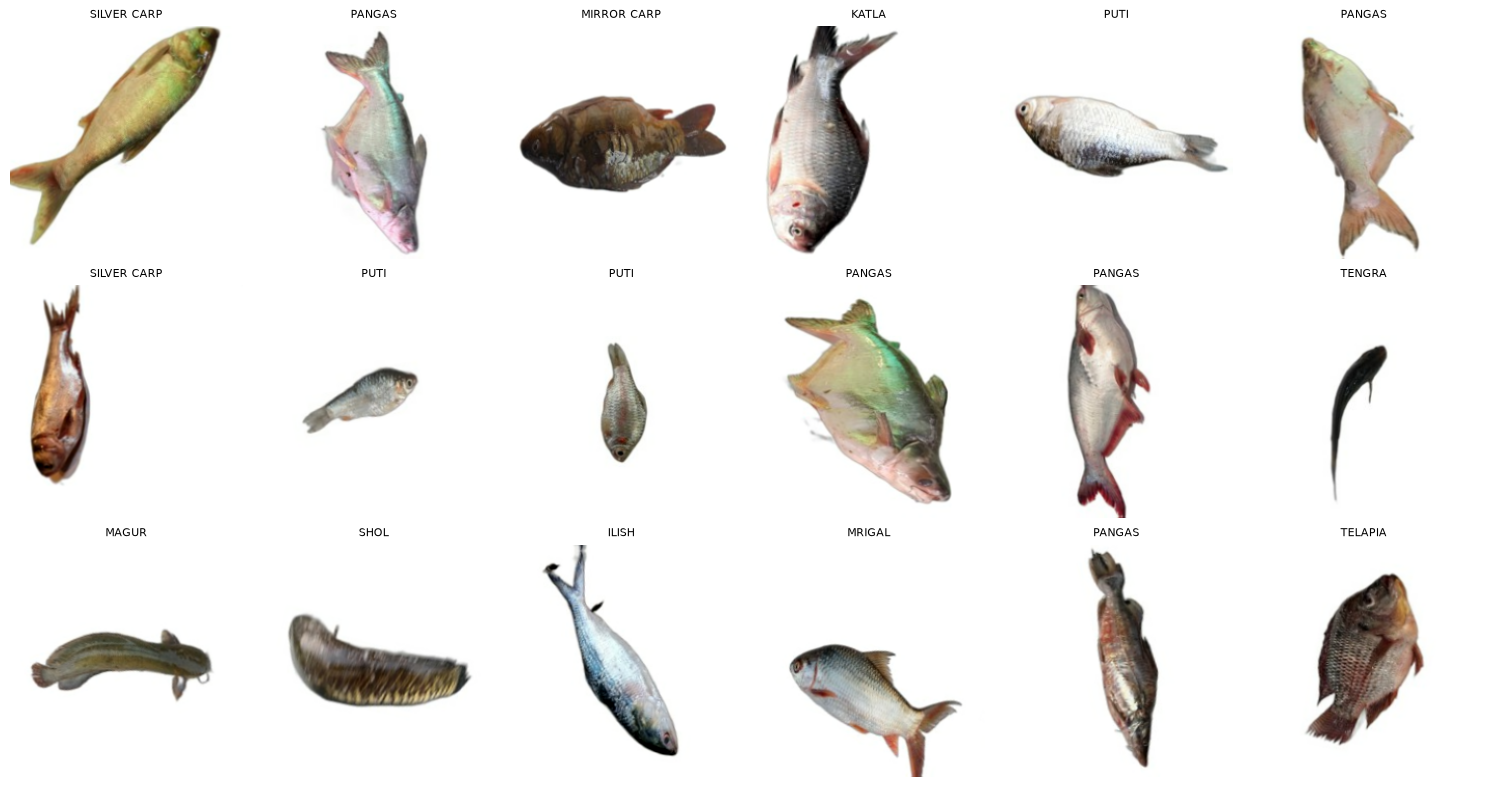

In [14]:
images, labels = next(iter(train_ds))

fig, axes = plt.subplots(3, 6, figsize=(15, 8))
axes = axes.ravel()
for i in range(18):
    axes[i].imshow(images[i].numpy())
    axes[i].set_title(IDX_TO_CLASS[int(labels[i])], fontsize=8)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

## 14. Save pipeline configuration

Both model notebooks must use this exact configuration for a fair comparison.

Saved to `custom_cnn/metrics/pipeline_config.json` and
`transfer_learning/metrics/pipeline_config.json`.

In [15]:
pipeline_info = {
    "img_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "normalization": "scale_to_0_1",
    "augmentation": [
        "horizontal_flip",
        "rotation_0.05",
        "zoom_0.10",
        "contrast_0.10",
    ],
    "train_size": int(len(train_df)),
    "val_size":   int(len(val_df)),
    "test_size":  int(len(test_df)),
    "num_classes": len(CLASS_NAMES),
    "class_names": CLASS_NAMES,
}

for target_dir in [CUSTOM_METRICS_DIR, TRANSFER_METRICS_DIR]:
    out = target_dir / "pipeline_config.json"
    with open(out, "w") as f:
        json.dump(pipeline_info, f, indent=2)
    print("Saved:", out)

print()
print(json.dumps(pipeline_info, indent=2))

Saved: d:\Dev\College\GenAI\bangladeshi-fish-cnn-classification\custom_cnn\metrics\pipeline_config.json
Saved: d:\Dev\College\GenAI\bangladeshi-fish-cnn-classification\transfer_learning\metrics\pipeline_config.json

{
  "img_size": [
    224,
    224
  ],
  "batch_size": 32,
  "seed": 42,
  "normalization": "scale_to_0_1",
  "augmentation": [
    "horizontal_flip",
    "rotation_0.05",
    "zoom_0.10",
    "contrast_0.10"
  ],
  "train_size": 3903,
  "val_size": 837,
  "test_size": 837,
  "num_classes": 15,
  "class_names": [
    "GRASS CARP",
    "ILISH",
    "KATLA",
    "KOI",
    "MAGUR",
    "MIRROR CARP",
    "MRIGAL",
    "PABDA",
    "PANGAS",
    "PUTI",
    "RUI",
    "SHOL",
    "SILVER CARP",
    "TELAPIA",
    "TENGRA"
  ]
}


## 15. Handoff notes for the model notebooks

Both `01_custom_cnn.ipynb` and `02_transfer_learning.ipynb` must:

1. **Not** re-split the dataset. Load the CSVs from `data/splits/`.
2. **Not** apply their own augmentation. Import the pipeline from `data_utils`.
3. Use the same class mapping: `CLASS_NAMES`, `CLASS_TO_IDX`, `IDX_TO_CLASS`.
4. Log per-epoch training and validation metrics to their own folder:
   - `custom_cnn/logs/training_log.csv`
   - `transfer_learning/logs/training_log.csv`
5. Save the best checkpoint to:
   - `custom_cnn/best_model/`
   - `transfer_learning/best_model/`
6. Save final metrics on the test set to their `metrics/` folder.

`03_comparison.ipynb` will then read those logs and metrics and produce the comparison.

### Preprocessing note for notebook 02

This notebook normalizes to `[0, 1]`. The transfer-learning notebook must
**either** use the same `[0, 1]` normalization **and** rely on the pretrained
model's internal preprocessing, **or** explicitly apply
`tf.keras.applications.<model>.preprocess_input`. Do not mix both. Whichever
is used must be documented in the transfer-learning notebook.

In [18]:
import importlib, data_utils
importlib.reload(data_utils)

from data_utils import (
    load_splits, get_train_ds, get_val_ds, get_test_ds,
    get_augmentation, get_class_weights,
    CLASS_NAMES, CLASS_TO_IDX, IDX_TO_CLASS,
)

train_ds = get_train_ds()
val_ds   = get_val_ds()
test_ds  = get_test_ds()

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Val   batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test  batches:", tf.data.experimental.cardinality(test_ds).numpy())
print("Class weights:", get_class_weights())

Train batches: 122
Val   batches: 27
Test  batches: 27
Class weights: {0: 0.922695035460993, 1: 1.596319018404908, 2: 0.8702341137123746, 3: 0.8559210526315789, 4: 1.3208121827411168, 5: 1.4375690607734806, 6: 1.172072072072072, 7: 1.0663934426229509, 8: 0.7288515406162465, 9: 0.9097902097902097, 10: 0.7227777777777777, 11: 1.2570048309178743, 12: 1.5488095238095239, 13: 0.9708955223880597, 14: 0.7128767123287671}
